# Lab 02 — Transfer learning và đánh giá

ResNet18 / DenseNet121; kết quả run `20261027T135216Z_cifar10_macintel_regularized64_fae6efd8`, CIFAR-10 45.000/5.000/10.000, seed 42, CPU 64×64. Head-only → fine-tune phần đuôi nhỏ với dropout và augmentation. [EDA](01_lab02_eda.ipynb) · [Báo cáo](../walkthrough_lab_02.md) · [Registry run đang xem](../outputs/selected_run.json)

In [1]:
from pathlib import Path
import os, sys
ROOT = Path(os.environ.get('LAB02_ROOT', '/Users/mac/Desktop/DEEP-V2/Lab-DL/labs/lab02')).expanduser()
if not ROOT.is_absolute() or not (ROOT / 'src/notebook_views.py').is_file(): raise RuntimeError('Set LAB02_ROOT to an existing absolute Lab02 directory containing src/notebook_views.py.')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
from src import notebook_views as view; import importlib; importlib.reload(view)
ROOT, RUN, OUT = view.context(); print('Run đã lưu:', RUN.name)

Run đã lưu: 20261027T135216Z_cifar10_macintel_regularized64_fae6efd8


## 1. Kiến trúc và freeze/unfreeze

Classifier đổi thành 10 đầu ra. Biểu đồ so sánh tham số được học; mở phần thu gọn để xem đầy đủ cấu trúc đã lưu. [Source](../src/models.py).

Run này mở ResNet18 `layer4.1` + classifier (4.725.770 tham số); DenseNet121 mở 4 dense layer cuối + norm5 + classifier (651.658 tham số). Dropout 0,2 trước Linear; BatchNorm running statistics giữ cố định. Head dùng feature cache cố định; fine-tune train dùng ảnh trực tiếp với random crop 32/padding reflect 4 và horizontal flip 0,5 trước preprocessing 64×64. Validation/test không augmentation. Đây là thay đổi kết hợp freeze/dropout/augmentation, chưa cô lập tác dụng từng yếu tố.

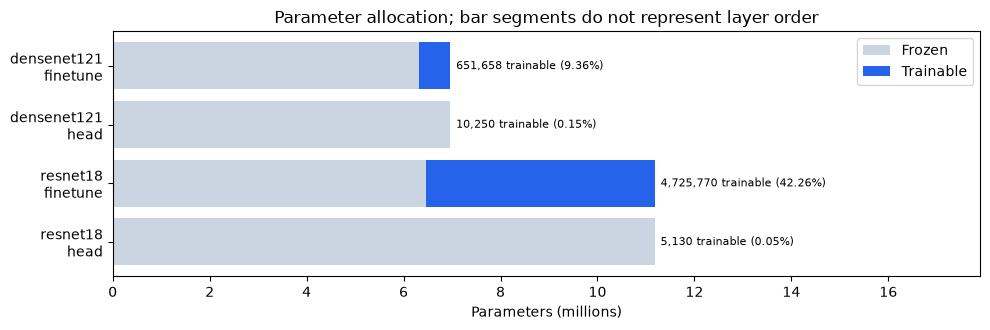

,model,stage,total,trainable,unfrozen_blocks
0,resnet18,head,11181642,5130,classifier
1,resnet18,finetune,11181642,4725770,layer4 + fc
2,densenet121,head,6964106,10250,classifier
3,densenet121,finetune,6964106,651658,denseblock4 + norm5 + classifier


In [2]:
view.architecture_visual(RUN, OUT)

## 2. Learning rate × batch size

Grid head đã chạy; chọn candidate bằng validation theo policy của run. Notebook không dùng test để chọn cấu hình.

Bảng HTML gồm 8 trial đã đo: learning rate {0,001; 0,01} × batch {64; 128} cho mỗi model, 10 epoch/trial, AdamW và weight decay 1e-4. Dòng xanh là cấu hình được chọn trong từng model theo validation. Accuracy có đơn vị %, loss không có đơn vị %, thời gian fit tính bằng phút và chưa gồm feature extraction. Batch lớn không bảo đảm nhanh hơn.

In [3]:
import json
import pandas as pd
from IPython.display import display

def show_search_table(table, caption):
    formats = {c: '{:.0e}' for c in table if c.endswith('LR')}
    formats.update({'Val accuracy (%)': '{:.2f}', 'Val loss': '{:.4f}', 'Fit (min)': '{:.2f}'})
    styled = table.style.hide(axis='index').format(formats, escape='html').set_caption(caption)
    styled = styled.apply(lambda row: ['background-color: #e6f4ea; color: #153d23; font-weight: 600' if row['Selected'] == 'Yes' else '' for _ in row], axis=1)
    styled = styled.set_properties(**{'padding': '8px 12px', 'border-bottom': '1px solid #cbd5e1'})
    display({'text/html': styled.to_html(), 'text/plain': table.to_string(index=False, formatters={c: f.format for c, f in formats.items() if c in table})}, raw=True)

head_rows = []
for model_name in pd.read_csv(RUN / 'comparison.csv').model.unique():
    trials = pd.read_csv(RUN / model_name / 'search_results.csv')
    chosen = json.loads((RUN / model_name / 'selection.json').read_text())['head']
    for trial in trials.sort_values(['lr', 'batch_size']).itertuples():
        head_rows.append({'Model': model_name, 'Trial': trial.trial, 'Head LR': trial.lr, 'Batch': trial.batch_size, 'Best epoch': trial.best_epoch, 'Val accuracy (%)': 100 * trial.best_val_accuracy, 'Val loss': trial.best_val_loss, 'Fit (min)': trial.train_seconds / 60, 'Selected': 'Yes' if trial.trial == chosen['trial'] else 'No'})
show_search_table(pd.DataFrame(head_rows), 'Head search: measured trials; green = selected within each model')

Model,Trial,Head LR,Batch,Best epoch,Val accuracy (%),Val loss,Fit (min),Selected
resnet18,0,1e-03,64,5,76.38,0.7019,0.35,No
resnet18,1,1e-03,128,6,76.40,0.6990,0.24,Yes
resnet18,2,1e-02,64,1,70.92,1.3375,0.34,No
resnet18,3,1e-02,128,1,72.10,1.0697,0.24,No
densenet121,0,1e-03,64,9,78.54,0.6373,0.28,No
densenet121,1,1e-03,128,8,79.04,0.6197,0.24,Yes
densenet121,2,1e-02,64,4,74.92,1.8555,0.31,No
densenet121,3,1e-02,128,9,74.44,1.3617,0.21,No


### Fine-tune: cấu hình đã chạy

Bảng HTML dưới có một candidate cho mỗi model: `last_units`, AdamW, backbone LR 1e-5, head LR 1e-4, không scheduler, 10 epoch cố định. Batch kế thừa selected head. Dòng xanh chỉ cấu hình được chọn trong từng model, không có nghĩa thắng model còn lại. Fine-tune bắt đầu từ selected head; checkpoint chọn bằng validation accuracy, hòa dùng validation loss. Loss ghi tại checkpoint được chọn, không nhất thiết là loss nhỏ nhất. Run này chưa so sánh nhiều LR fine-tune, SGD/cosine hoặc nhiều độ sâu.

In [4]:
fine_rows = []
for model_name in pd.read_csv(RUN / 'comparison.csv').model.unique():
    trials = pd.read_csv(RUN / model_name / 'finetune_search_results.csv')
    selected = json.loads((RUN / model_name / 'selection.json').read_text())
    for trial in trials.itertuples():
        fine_rows.append({'Model': model_name, 'Trial': trial.trial, 'Backbone LR': trial.backbone_lr, 'Head LR': trial.head_lr, 'Batch': selected['head']['batch_size'], 'Unfreeze': trial.unfreeze, 'Best epoch': trial.best_epoch, 'Val accuracy (%)': 100 * trial.best_val_accuracy, 'Val loss': trial.best_val_loss, 'Fit (min)': trial.train_seconds / 60, 'Selected': 'Yes' if trial.trial == selected['finetune']['trial'] else 'No'})
show_search_table(pd.DataFrame(fine_rows), 'Fine-tune: selection is within each model; fit time excludes head search')

Model,Trial,Backbone LR,Head LR,Batch,Unfreeze,Best epoch,Val accuracy (%),Val loss,Fit (min),Selected
resnet18,0,1e-05,1e-04,128,last_units,9,80.68,0.5573,51.75,Yes
densenet121,0,1e-05,1e-04,128,last_units,10,80.66,0.5525,92.63,Yes


## 3. Training, TensorBoard và learning curves

Run đã hoàn tất: mỗi head trial 10/10 và fine-tune 10/10 epoch cho cả hai model. Hàng trên: **HEAD ONLY**, hàng dưới: **FINE-TUNE**; xanh liền = train, cam đứt = validation; ngôi sao là checkpoint được chọn.

Dừng vì hết ngân sách (`epoch_budget_exhausted`), không dùng early stopping. ResNet chọn epoch 9 (val accuracy 80,68%); DenseNet chọn epoch 10 (80,66%). Validation loss còn giảm cuối run nên chưa xác lập hội tụ; chưa thấy dấu hiệu overfit rõ trong 10 epoch. Train có dropout/augmentation nên không so train–validation gap như hai phép đo cùng điều kiện. Bảng phân biệt run này với config GPU `tuned.json` chưa chạy.

TensorBoard bên dưới dựng từ CSV scalar đã lưu, tách head/fine-tune; không phải dashboard live. Khi train, mở terminal thứ hai: `tensorboard --logdir outputs/runs --port 6006`. Checkpoint tốt nhất chọn theo validation accuracy, loss phân xử khi bằng nhau.

,Model,Stage,Recorded epochs,Original configured budget,New budget (NOT RUN)
0,resnet18,Head,10,10,10
1,resnet18,Fine-tune,10,10,"min 10, max 30"
2,densenet121,Head,10,10,10
3,densenet121,Fine-tune,10,10,"min 10, max 30"


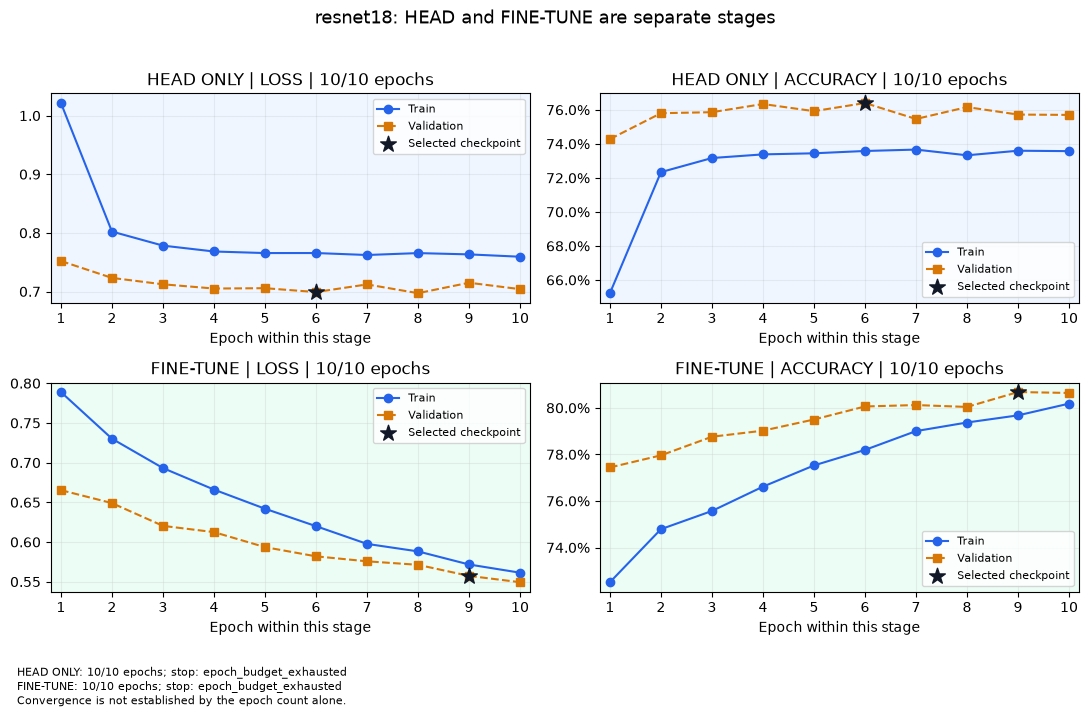

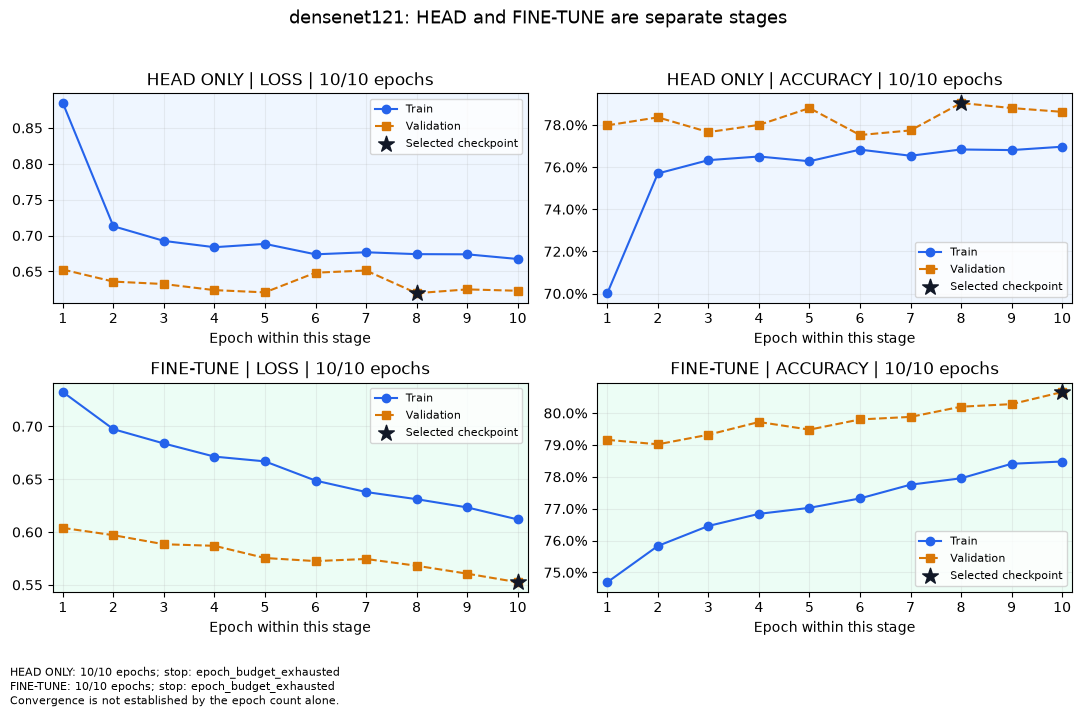

In [5]:
view.epoch_budget(RUN, ROOT)
view.tensorboard_evidence(RUN)
view.learning_curves(RUN, OUT)

## 4. Kết quả tổng trên test

Đọc theo thứ tự loss, accuracy, macro precision, macro recall/TPR và macro F1. Macro là trung bình metric từng lớp với trọng số bằng nhau; TPR chính là recall, không thêm cột trùng. Macro F1 là trung bình F1 từng lớp, không tính lại từ macro precision/recall.

Loss là mức phạt trung bình theo xác suất nhãn thật, càng thấp càng tốt và không có đơn vị %. Ví dụ một ảnh thật là cat: p(cat)=0,9 có loss khoảng 0,105; p(cat)=0,1 có loss khoảng 2,303. Mỗi cột dưới là trung bình toàn test của một điều kiện. P/R/F1/accuracy dùng %, càng cao càng tốt. Chọn cấu hình bằng validation, không chọn bằng test.

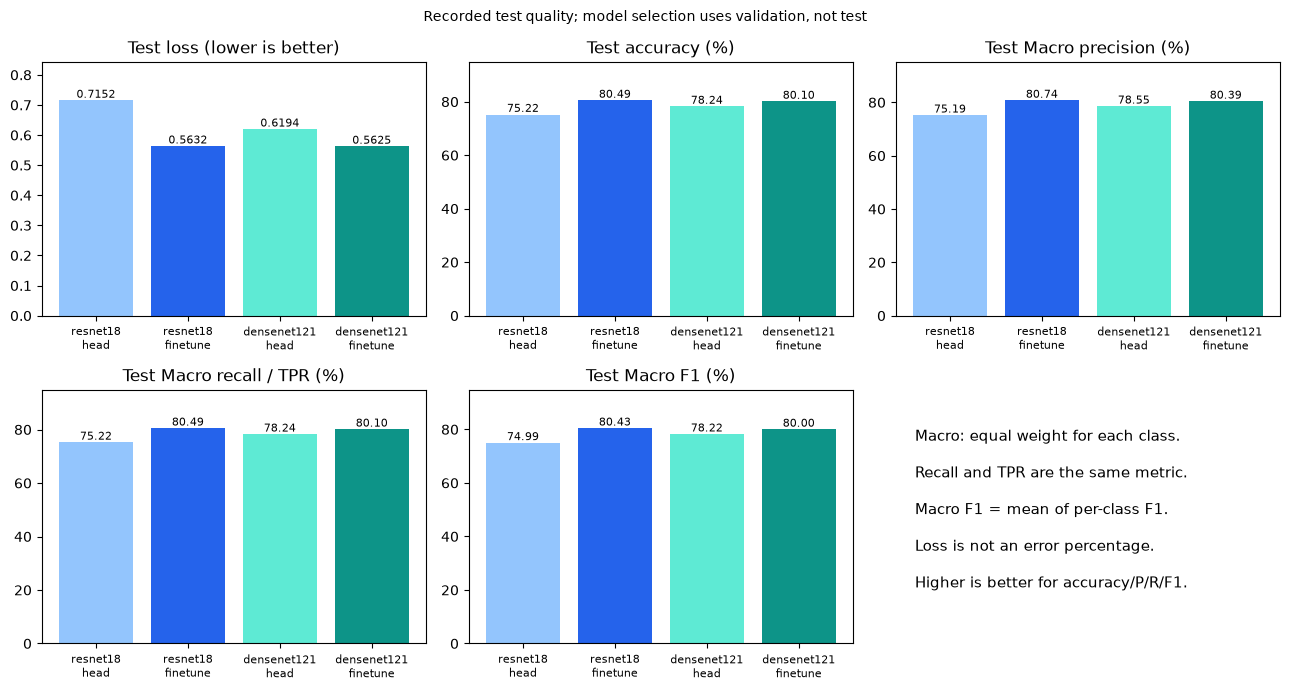

,model,stage,loss,accuracy (%),macro_precision (%),macro_recall (%),macro_f1 (%),execution
0,resnet18,head,0.7152,75.22,75.1867,75.22,74.9879,pooled_feature_cache
1,resnet18,finetune,0.5632,80.49,80.7357,80.49,80.4263,full_image_forward
2,densenet121,head,0.6194,78.24,78.5525,78.24,78.2182,pooled_feature_cache
3,densenet121,finetune,0.5625,80.10,80.3940,80.10,79.9983,full_image_forward


In [6]:
view.quality_cost(RUN, OUT)

## 5. Phân tích lỗi theo lớp

Một heatmap duy nhất theo thứ tự Precision → Recall/TPR → F1 → FPR; bỏ biểu đồ cột recall/FPR bị lặp. Mỗi hàng là một lớp, mỗi cột là model; hình dùng kết quả fine-tune. Bảng CSV giữ cả head/fine-tune; bảng ngắn bên dưới chỉ hiển thị các lớp F1 thấp nhất.

Precision: trong các dự đoán thuộc lớp này, bao nhiêu đúng? Recall/TPR: trong ảnh thật của lớp này, tìm đúng bao nhiêu? FPR: trong ảnh không thuộc lớp này, bao nhiêu bị gán nhầm vào lớp? Recall/TPR và FPR ở đây tính từ dự đoán argmax, không phải đường ROC qua nhiều ngưỡng.

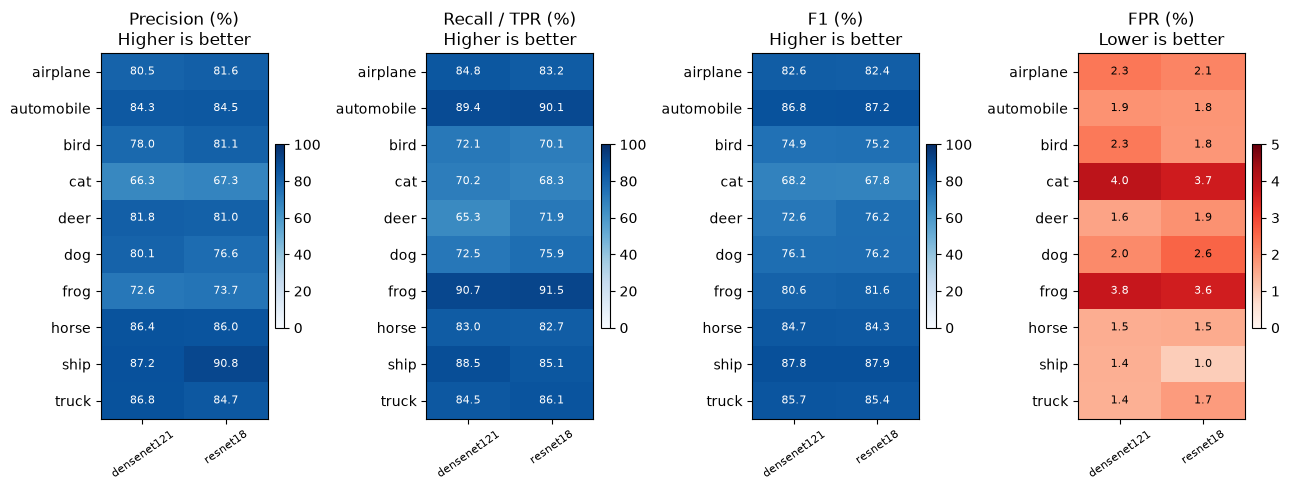

,model,stage,class,precision,recall_tpr,f1,fpr
13,resnet18,finetune,cat,0.6729,0.683,0.6779,0.0369
33,densenet121,finetune,cat,0.6629,0.702,0.6819,0.0397
34,densenet121,finetune,deer,0.8183,0.653,0.7264,0.0161
12,resnet18,finetune,bird,0.8113,0.701,0.7521,0.0181


In [7]:
view.errors(RUN, OUT)

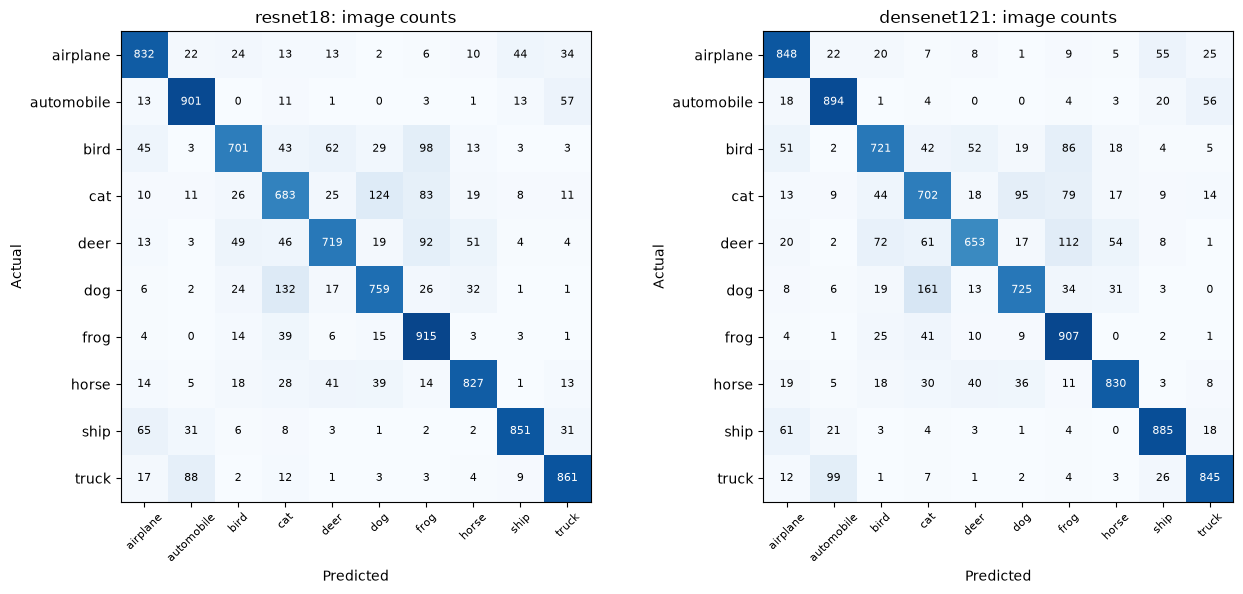

,model,actual,predicted,count,within_actual_class_pct
0,resnet18,dog,cat,132,13.2
1,resnet18,cat,dog,124,12.4
2,resnet18,bird,frog,98,9.8
3,densenet121,dog,cat,161,16.1
4,densenet121,deer,frog,112,11.2
5,densenet121,truck,automobile,99,9.9


In [8]:
view.evidence(RUN, 'confusion_matrix')

Đọc confusion matrix theo hàng nhãn thật; bảng phía trên chỉ ra lớp yếu của run đang xem. Lưới dưới chọn tối đa 8 đúng và 8 sai để minh họa, không đại diện accuracy.

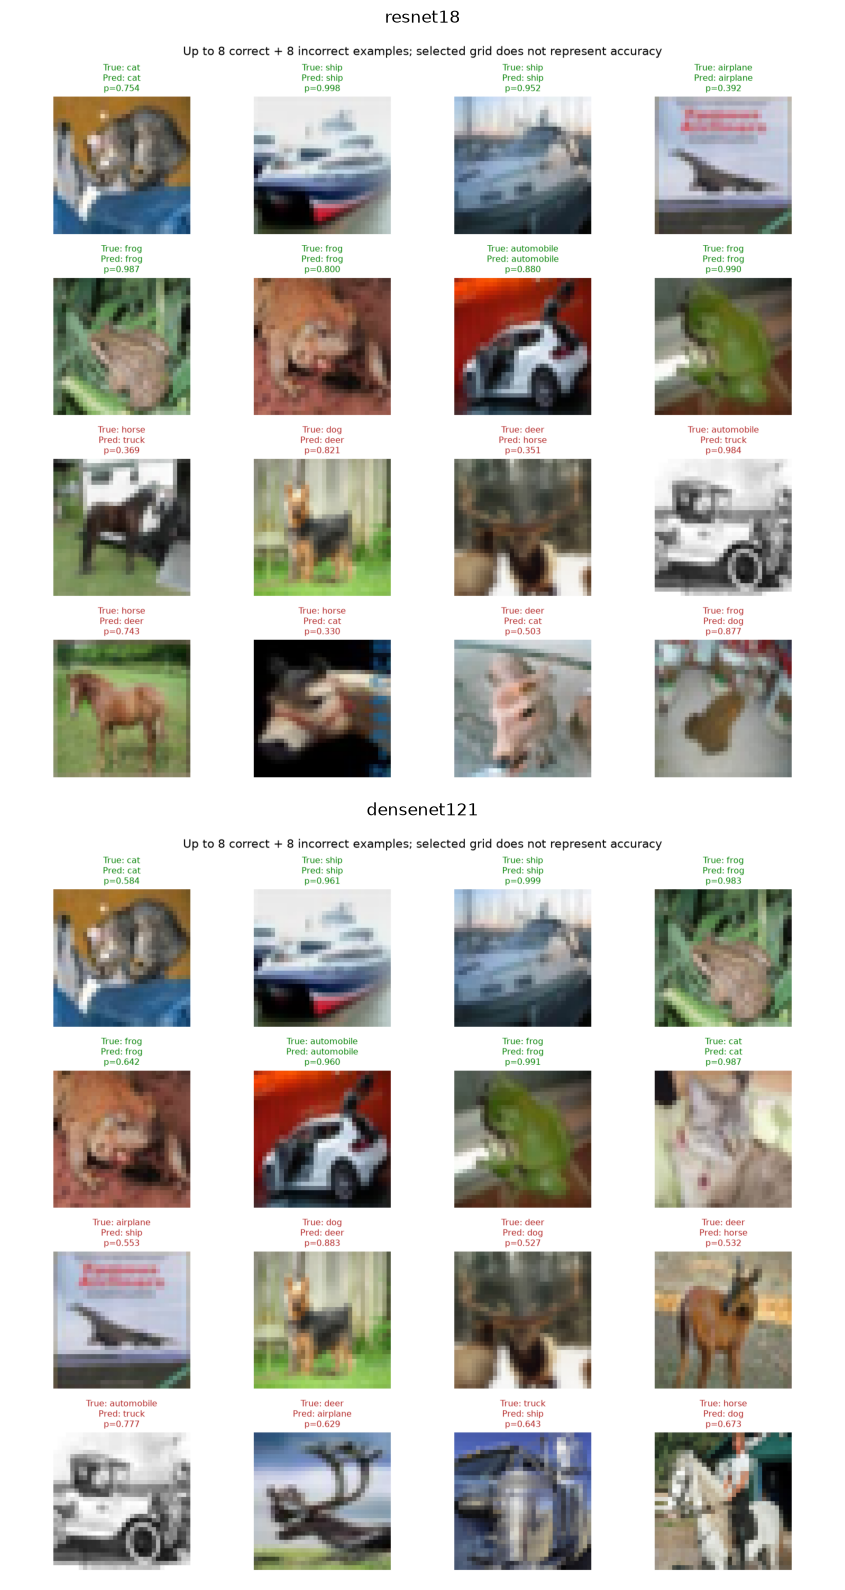

In [9]:
view.evidence(RUN, 'prediction_examples')

## 6. ROC và Precision–Recall curves

ROC: trục X là FPR, trục Y là TPR; gần góc trên trái hơn thường tốt hơn. PR: trục X là recall, trục Y là precision; ưu tiên precision cao ở recall quan tâm. Mỗi đường xét một lớp so với tất cả lớp còn lại (one-vs-rest), thay đổi ngưỡng xác suất để tạo nhiều điểm.

Cell dưới tính ROC/PR trực tiếp từ `test_predictions.npz` của fine-tune: không train hoặc inference lại, không lấy hình run cũ. Mỗi model một hình riêng gồm ROC và PR theo lớp; PNG và CSV được lưu tại `outputs/review/<run>/<model>/`. Legend ROC ghi AUC, PR ghi average precision (AP), không phải F1 hoặc accuracy. AUC không thay thế metric argmax ở mục 4–5.

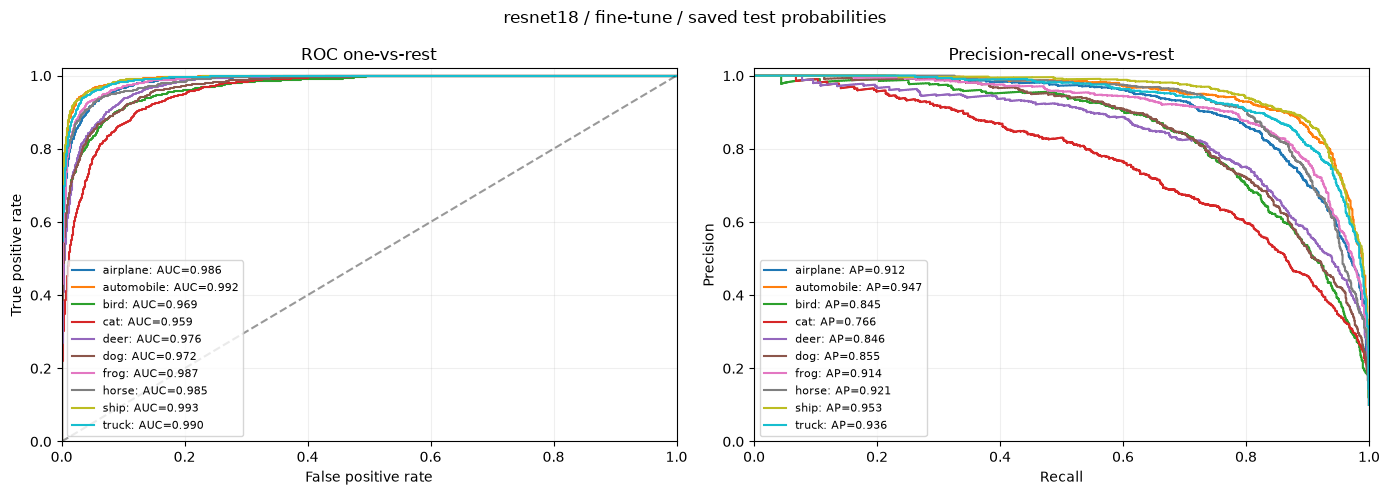

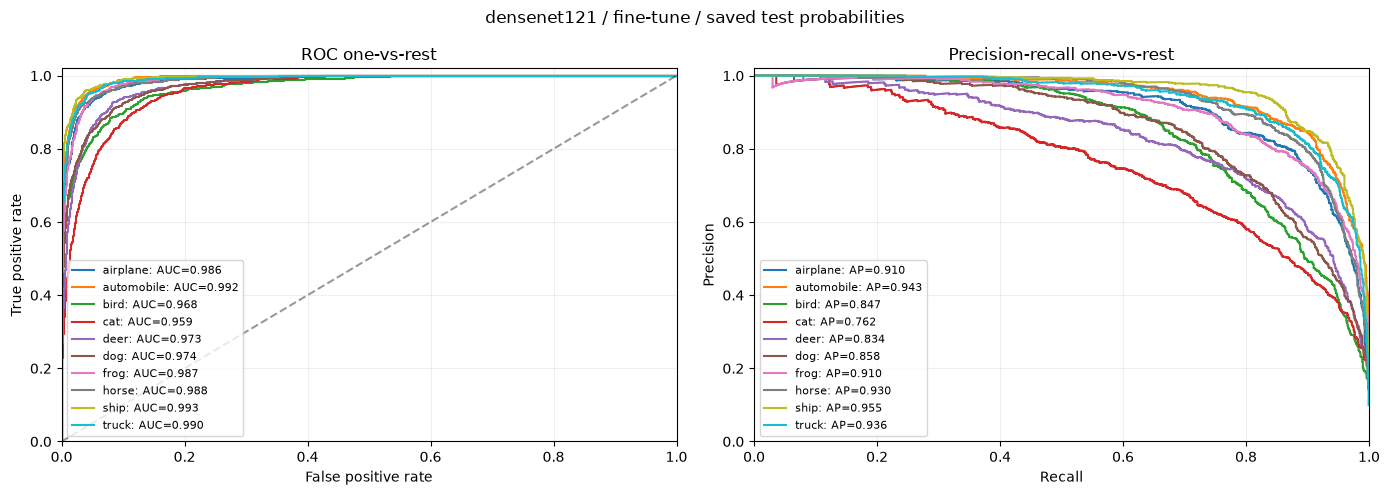

,Model,Test samples,Macro ROC AUC,Macro AP
0,resnet18,10000,0.9808,0.8895
1,densenet121,10000,0.9809,0.8887


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from src.eda import CLASSES
from src.reporting import save_figure

roc_summary = []
for model_name in pd.read_csv(RUN / 'comparison.csv').model.unique():
    prediction_path = RUN / model_name / 'finetune/test_predictions.npz'
    if not prediction_path.is_file():
        raise FileNotFoundError(f'Missing saved test predictions: {prediction_path}')
    with np.load(prediction_path) as saved:
        labels, probabilities = saved['labels'], saved['probabilities']
    if probabilities.shape != (len(labels), len(CLASSES)) or not np.isfinite(probabilities).all():
        raise ValueError(f'Invalid saved probabilities for {model_name}')
    np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-6)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    class_scores = []
    for class_id, class_name in enumerate(CLASSES):
        target = labels == class_id
        if not target.any() or target.all():
            raise ValueError(f'ROC requires positive and negative samples: {model_name}/{class_name}')
        fpr, tpr, _ = roc_curve(target, probabilities[:, class_id])
        precision, recall, _ = precision_recall_curve(target, probabilities[:, class_id])
        roc_auc = auc(fpr, tpr)
        ap = average_precision_score(target, probabilities[:, class_id])
        axes[0].plot(fpr, tpr, label=f'{class_name}: AUC={roc_auc:.3f}')
        axes[1].step(recall, precision, where='post', label=f'{class_name}: AP={ap:.3f}')
        class_scores.append({'class': class_name, 'roc_auc_ovr': roc_auc, 'average_precision_ovr': ap})
    axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
    axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC one-vs-rest', xlim=(0, 1), ylim=(0, 1.02))
    axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-recall one-vs-rest', xlim=(0, 1), ylim=(0, 1.02))
    for ax in axes:
        ax.legend(fontsize=8, loc='lower left'); ax.grid(alpha=0.2)
    fig.suptitle(f'{model_name} / fine-tune / saved test probabilities')
    fig.tight_layout()
    destination = OUT / model_name
    destination.mkdir(parents=True, exist_ok=True)
    save_figure(fig, destination / 'roc_pr.png', dpi=150, bbox_inches='tight')
    display(fig); plt.close(fig)
    scores = pd.DataFrame(class_scores)
    scores.to_csv(destination / 'roc_pr_metrics.csv', index=False)
    roc_summary.append({'Model': model_name, 'Test samples': len(labels), 'Macro ROC AUC': scores.roc_auc_ovr.mean(), 'Macro AP': scores.average_precision_ovr.mean()})
display(pd.DataFrame(roc_summary).round(4))

## 7. Chi phí thí nghiệm

Phân biệt tổng chi phí tìm cấu hình với chi phí công thức được chọn và thời gian chạy toàn test. Biểu đồ trái cộng dồn feature extraction + mọi head trial + mọi fine-tune trial; biểu đồ phải tách training recipe và test. Recipe được tổng hợp từ số đo, không phải retrain mới. Cả hai model fine-tune bằng full-image forward; control cũ dùng cached frozen prefix nên không quy chênh thời gian giữa hai run cho riêng kiến trúc hoặc số tham số mở.

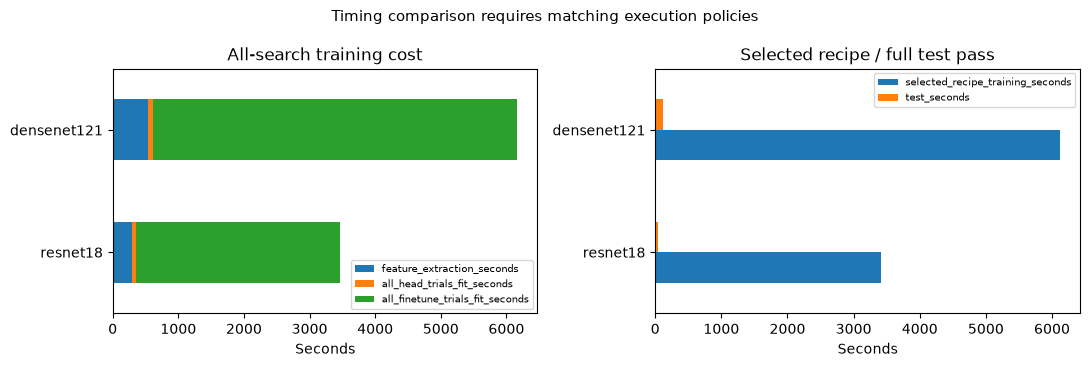

,model,execution,pipeline_training_seconds,selected_recipe_training_seconds,test_seconds
1,resnet18,full_image_forward,3463.97,3407.84,35.12
3,densenet121,full_image_forward,6165.32,6117.23,123.32


,model,val_accuracy,val_loss,time_comparable
0,resnet18,0.8068,0.55732,True


In [11]:
view.efficiency(RUN, OUT)

## 8. Kiểm tra artifact để mở TensorBoard và inference

Bảng dưới kiểm tra event files và checkpoint hiện có, không kiểm tra server live. CSV/PNG cho phép trình bày lịch sử nhưng không thay thế event files và weights. Log nằm trong từng trial để tránh trộn cấu hình.

In [12]:
view.monitoring_status(RUN)

,run,event_files,best_checkpoints,live_server,historical_server_record
0,20261027T135216Z_cifar10_macintel_regularized6...,22,12,not probed,False


## 9. Save/load và kết luận

Đã chạy lại inference trên 10.000 ảnh test cho cả bốn checkpoint (head/fine-tune của hai model), không train lại. Đã đối chiếu SHA256 checkpoint, thứ tự indices, nhãn và prediction xuất mới với run gốc. Bảng dưới đọc kết quả lần kiểm chứng mới; thực thi notebook chỉ trình bày artifact, không chạy lại inference. [Bằng chứng](../../../.agents/lab02-test-review/20261027T135216Z_cifar10_macintel_regularized64_fae6efd8/verification.json).

Cả bốn điều kiện có cùng nhãn dự đoán argmax với lần trước và metric tổng không đổi. Sai lệch xác suất tối đa giữa hai lần inference khoảng 1,25e-6; không khẳng định xác suất giống từng bit. Save/load mới thực sự lưu state_dict ra file tạm rồi tải vào model mới: sai lệch xác suất bằng 0 trên 8 mẫu mỗi điều kiện. Kiểm chứng này không chứng minh độ chính xác trên dữ liệu ngoài CIFAR-10.

**Kết quả run mới:** ResNet18 head → fine-tune: test accuracy 75,22% → 80,49%, Macro F1 0,7499 → 0,8043. DenseNet121: 78,24% → 80,10%, Macro F1 0,7822 → 0,8000. Hai giai đoạn có ngân sách khác nhau nên chưa cô lập tác động unfreeze. Khuyến nghị trong run là ResNet18 theo validation 80,68% so với 80,66%; một seed và chênh 0,02 điểm phần trăm chưa chứng minh ưu thế kiến trúc.

**So với control `20261027T083044Z_cifar10_macintel_cpu_control64_db231b28`:** test accuracy ResNet18 giảm 83,59% → 80,49% (-3,10 điểm phần trăm); DenseNet121 giảm 82,99% → 80,10% (-2,89 điểm phần trăm). Regularization mới chưa cải thiện trong ngân sách 10 epoch; không quy nguyên nhân riêng cho dropout, augmentation hay freeze.

**Phân tích lỗi:** ResNet cat recall 68,3%, dog → cat 132/1.000 ảnh; DenseNet deer recall 65,3%, dog → cat 161/1.000 ảnh. Có dự đoán sai tự tin cao: ResNet automobile → truck p=0,984. Lưới ảnh minh họa không đại diện toàn test; không suy ra nguyên nhân nền/độ sáng từ confusion matrix.

**Giới hạn:** validation loss vẫn giảm cuối run, chưa chứng minh hội tụ. Config GPU 224×224 chưa chạy. Báo cáo tự sinh `report_vi.md` còn câu không augmentation trái với config; notebook này mô tả theo config và artifact thực tế. Lần kiểm tra run gốc trước đó: 173/173 hash trong manifest khớp. Lần test lại lưu riêng trong `.agents/lab02-test-review/`, không ghi đè run gốc hoặc dùng test để chọn lại checkpoint.

In [13]:
import json, pandas as pd
verification = ROOT.parents[1] / '.agents/lab02-test-review' / RUN.name / 'verification.json'
checked = json.loads(verification.read_text())
assert Path(checked['run']).resolve() == RUN.resolve(), 'Verification run mismatch'
rows = [dict(model=r['model'], stage=r['stage'], **r['metrics'], same_predictions=r['same_argmax_predictions'], probability_delta=r['previous_probability_max_error'], roundtrip_samples=r['roundtrip_samples'], roundtrip_delta=r['roundtrip_max_error'], roundtrip_passed=r['roundtrip_passed']) for r in checked['results']]
display(pd.DataFrame(rows))

,model,stage,test_samples,accuracy,macro_f1,macro_precision,macro_recall,loss,same_predictions,probability_delta,roundtrip_samples,roundtrip_delta,roundtrip_passed
0,resnet18,head_selected,10000,0.7522,0.749879,0.751867,0.7522,0.715181,True,6.854534e-07,8,0.0,True
1,resnet18,finetune,10000,0.8049,0.804263,0.807357,0.8049,0.563231,True,9.536743e-07,8,0.0,True
2,densenet121,head_selected,10000,0.7824,0.782182,0.785525,0.7824,0.619436,True,1.251698e-06,8,0.0,True
3,densenet121,finetune,10000,0.8010,0.799983,0.803940,0.8010,0.562481,True,7.748604e-07,8,0.0,True


Tuning GPU: `python scripts/run.py --config config/tuned.json --device cuda`. Xem trước ngân sách bằng `--dry-run`; lặp seed bằng `--seed 43`/`--seed 44`, split vẫn giữ seed 42. [Source training](../src/experiment.py) · [Thiết kế và giới hạn](../walkthrough_lab_02.md#15-loss-function-and-optimization-design).

Đề xuất tiếp theo, chưa thực thi: chốt ngân sách để kiểm tra hội tụ bằng validation, sau đó tách từng thay đổi freeze/dropout/augmentation với cùng điều kiện và nhiều seed. Không dùng test để điều chỉnh liên tục. Chưa thể kết luận tăng epoch sẽ cải thiện test accuracy.